# Project-I: Research Article Classification
Classify peer-reviewed abstracts into **Science**, **Business** and **Social Science**.

**Pipeline:** load data -> EDA -> text preprocessing -> TF-IDF -> 6 classifiers (Logistic Regression, Decision Tree, Naive Bayes, kNN, SVM, Random Forest) -> metrics, confusion matrices, feature visualisations -> save best model for the Streamlit demo.

Dataset: `abstracts_dataset.csv` (built with `collect_data.py` from OpenAlex, which indexes the same literature as Scopus / Web of Science).

In [1]:
import re, warnings, joblib
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.naive_bayes import MultinomialNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import LinearSVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, precision_recall_fscore_support,
                             confusion_matrix, ConfusionMatrixDisplay, classification_report)
warnings.filterwarnings('ignore')
sns.set_theme(style='whitegrid')
SEED = 42

## 1. Load the dataset

In [2]:
import os
CSV = 'abstracts_dataset.csv'
if not os.path.exists(CSV):          # Colab: upload the file when prompted
    from google.colab import files
    files.upload()
df = pd.read_csv(CSV).dropna(subset=['abstract', 'label']).drop_duplicates(subset='abstract')
print(df.shape)
df.head()

(1500, 4)


,title,abstract,year,label
0,Three pillars of sustainability: in search of ...,"The three-pillar conception of (social, econom...",2019,Social Science
1,Interpreting Effect Sizes of Education Interve...,Researchers commonly interpret effect sizes by...,2020,Social Science
2,Updated analysis of KEYNOTE-024: Pembrolizumab...,"PURPOSE In the randomized, open-label, phase I...",2019,Science
3,Scrublet: Computational Identification of Cell...,Single-cell RNA-sequencing has become a widely...,2019,Science
4,Temporal data classification and forecasting u...,Time-series analysis including forecasting is ...,2019,Science


## 2. Exploratory analysis

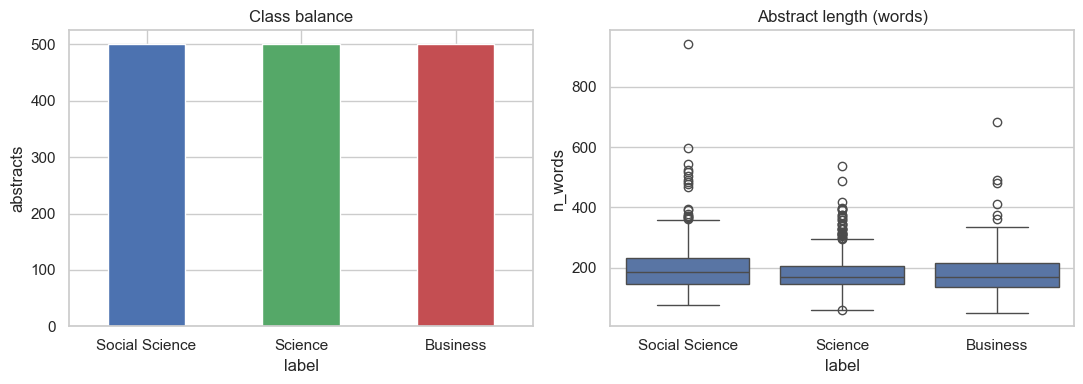

label
Social Science    500
Science           500
Business          500
Name: count, dtype: int64


In [3]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
df['label'].value_counts().plot.bar(ax=ax[0], color=['#4C72B0', '#55A868', '#C44E52'])
ax[0].set_title('Class balance'); ax[0].set_ylabel('abstracts'); ax[0].tick_params(axis='x', rotation=0)
df['n_words'] = df['abstract'].str.split().str.len()
sns.boxplot(data=df, x='label', y='n_words', ax=ax[1]); ax[1].set_title('Abstract length (words)')
plt.tight_layout(); plt.show()
print(df['label'].value_counts())

## 3. Preprocessing
Lower-casing, removal of publisher boilerplate (copyright lines, "Abstract" headers), HTML tags, numbers and punctuation; English stop-words are removed by the TF-IDF vectoriser. Word 1-2-grams are used as features.

In [4]:
def clean_text(t):
    t = str(t).lower()
    t = re.sub(r'<[^>]+>', ' ', t)                      # html / xml tags
    t = re.sub(r'(©|copyright|\(c\)).{0,80}', ' ', t)   # copyright lines
    t = re.sub(r'^\s*abstract[:.\s]*', ' ', t)
    t = re.sub(r'[^a-z\s]', ' ', t)                     # numbers, punctuation
    return re.sub(r'\s+', ' ', t).strip()

df['clean'] = df['abstract'].apply(clean_text)
df[['abstract', 'clean']].head(3).T

,0,1,2
abstract,"The three-pillar conception of (social, econom...",Researchers commonly interpret effect sizes by...,"PURPOSE In the randomized, open-label, phase I..."
clean,the three pillar conception of social economic...,researchers commonly interpret effect sizes by...,purpose in the randomized open label phase iii...


## 4. Train / test split (stratified 80 / 20)

In [5]:
X_train, X_test, y_train, y_test = train_test_split(
    df['clean'], df['label'], test_size=0.2, stratify=df['label'], random_state=SEED)
labels = sorted(df['label'].unique())
print(len(X_train), 'train |', len(X_test), 'test')

1200 train | 300 test


## 5. Train and compare the six classifiers

In [6]:
def tfidf():
    return TfidfVectorizer(stop_words='english', ngram_range=(1, 2), min_df=2, max_df=0.9,
                           sublinear_tf=True, max_features=30000)

models = {
    'Logistic Regression': LogisticRegression(max_iter=2000, C=5, random_state=SEED),
    'Decision Tree':       DecisionTreeClassifier(max_depth=30, random_state=SEED),
    'Naive Bayes':         MultinomialNB(alpha=0.1),
    'kNN':                 KNeighborsClassifier(n_neighbors=7, metric='cosine'),
    'SVM (linear)':        LinearSVC(C=1.0, random_state=SEED),
    'Random Forest':       RandomForestClassifier(n_estimators=300, n_jobs=-1, random_state=SEED),
}
cv = StratifiedKFold(5, shuffle=True, random_state=SEED)
pipes, preds, rows = {}, {}, []
for name, clf in models.items():
    pipe = Pipeline([('tfidf', tfidf()), ('clf', clf)])
    cv_acc = cross_val_score(pipe, X_train, y_train, cv=cv, scoring='accuracy', n_jobs=-1)
    pipe.fit(X_train, y_train)
    p = pipe.predict(X_test)
    pr, rc, f1, _ = precision_recall_fscore_support(y_test, p, average='macro')
    rows.append({'Model': name, 'CV accuracy (mean)': cv_acc.mean(), 'CV std': cv_acc.std(),
                 'Test accuracy': accuracy_score(y_test, p), 'Precision (macro)': pr,
                 'Recall (macro)': rc, 'F1 (macro)': f1})
    pipes[name], preds[name] = pipe, p
results = pd.DataFrame(rows).set_index('Model').sort_values('F1 (macro)', ascending=False)
results.round(4)

,CV accuracy (mean),CV std,Test accuracy,Precision (macro),Recall (macro),F1 (macro)
Model,,,,,,
Logistic Regression,0.8458,0.0147,0.8700,0.8714,0.8700,0.8696
Naive Bayes,0.8492,0.0138,0.8700,0.8716,0.8700,0.8694
SVM (linear),0.8467,0.0148,0.8667,0.8679,0.8667,0.8663
Random Forest,0.8142,0.0294,0.8300,0.8303,0.8300,0.8281
kNN,0.8200,0.0148,0.8200,0.8186,0.8200,0.8189
Decision Tree,0.6642,0.0312,0.6533,0.6539,0.6533,0.6536


## 6. Model comparison

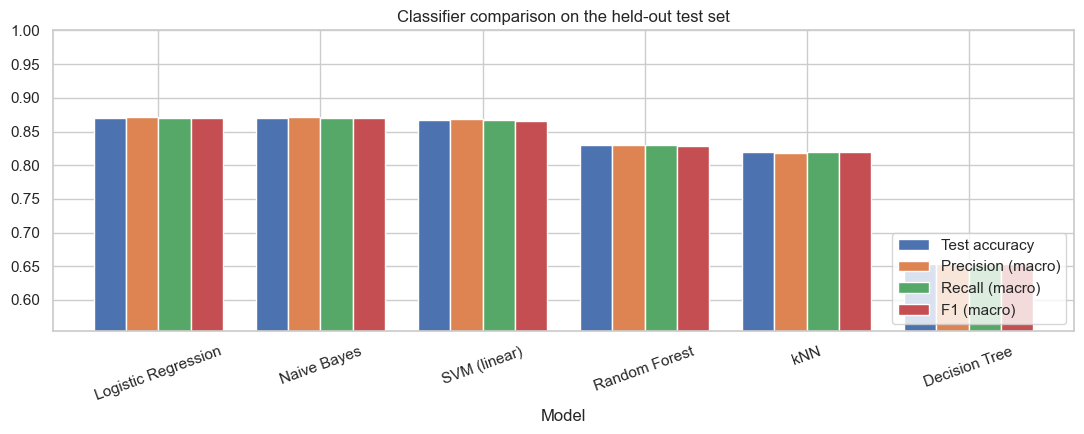

In [7]:
metrics = ['Test accuracy', 'Precision (macro)', 'Recall (macro)', 'F1 (macro)']
ax = results[metrics].plot.bar(figsize=(11, 4.5), width=0.8)
ax.set_ylim(max(0, results[metrics].min().min() - 0.1), 1.0)
ax.set_title('Classifier comparison on the held-out test set'); ax.tick_params(axis='x', rotation=20)
ax.legend(loc='lower right'); plt.tight_layout(); plt.show()

## 6b. Hyperparameter tuning (Logistic Regression)
5-fold grid search on the **training set only**, scored by macro-F1. The test set is looked at once, at the end.

In [8]:
from sklearn.model_selection import GridSearchCV
gpipe = Pipeline([('tfidf', TfidfVectorizer(stop_words='english', sublinear_tf=True)),
                  ('clf', LogisticRegression(max_iter=2000, random_state=SEED))])
grid = {'tfidf__ngram_range': [(1, 1), (1, 2)], 'tfidf__min_df': [2, 5],
        'tfidf__max_features': [10000, 30000, None], 'clf__C': [0.5, 1, 5, 10, 20]}
gs = GridSearchCV(gpipe, grid, cv=5, scoring='f1_macro', n_jobs=-1).fit(X_train, y_train)
tuned_acc = accuracy_score(y_test, gs.predict(X_test))
default_acc = results.loc['Logistic Regression', 'Test accuracy']
print('Best params      :', gs.best_params_)
print('Best CV macro-F1 :', round(gs.best_score_, 4))
print('Tuned test acc   :', round(tuned_acc, 4), '| default test acc:', round(default_acc, 4))
print('Keeping the default model unless tuning clearly helps.')

Best params      : {'clf__C': 10, 'tfidf__max_features': 10000, 'tfidf__min_df': 2, 'tfidf__ngram_range': (1, 2)}
Best CV macro-F1 : 0.8436
Tuned test acc   : 0.8567 | default test acc: 0.87
Keeping the default model unless tuning clearly helps.


## 7. Confusion matrices

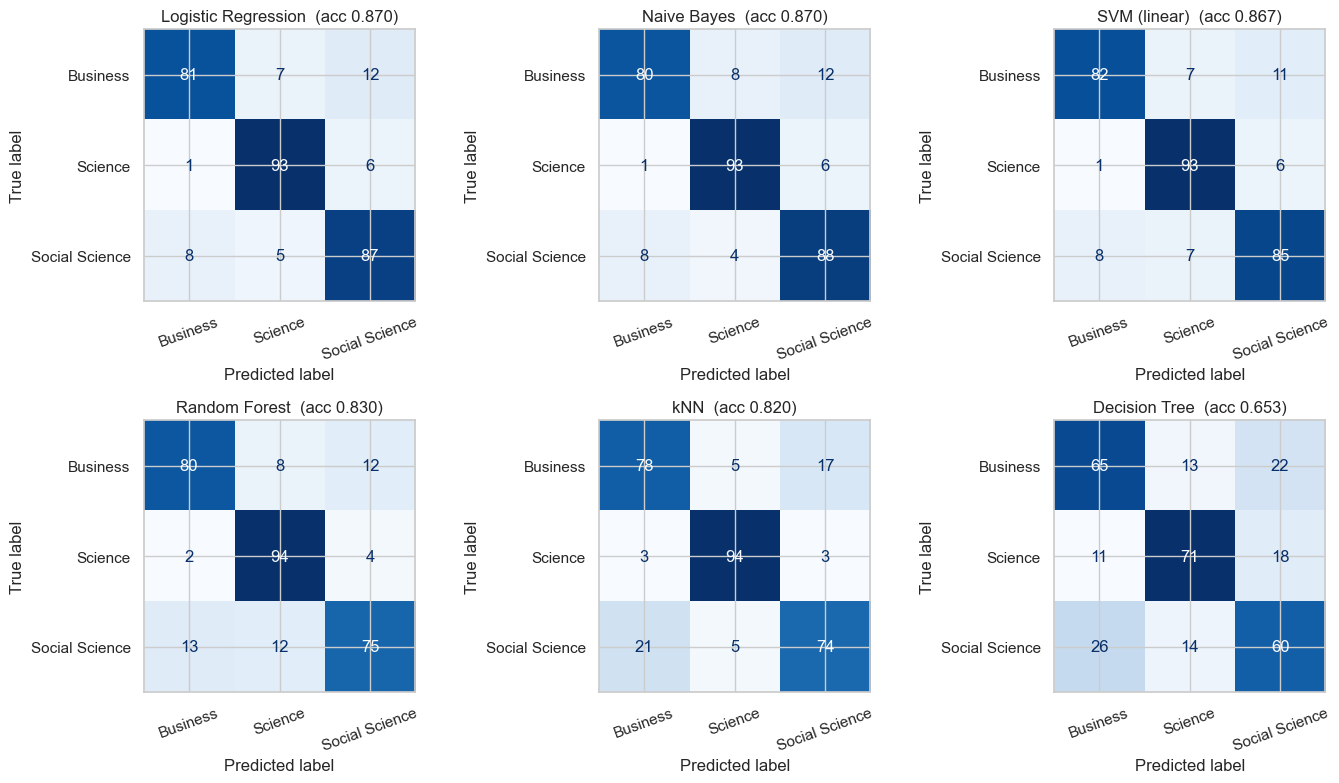

In [9]:
fig, axes = plt.subplots(2, 3, figsize=(14, 8))
for ax, name in zip(axes.ravel(), results.index):
    ConfusionMatrixDisplay.from_predictions(y_test, preds[name], labels=labels, ax=ax,
                                            cmap='Blues', colorbar=False, xticks_rotation=20)
    ax.set_title(f"{name}  (acc {accuracy_score(y_test, preds[name]):.3f})")
plt.tight_layout(); plt.show()

## 8. Per-class report for the best model

In [10]:
best = results.index[0]
print('Best model:', best)
print(classification_report(y_test, preds[best], digits=3))

Best model: Logistic Regression
                precision    recall  f1-score   support

      Business      0.900     0.810     0.853       100
       Science      0.886     0.930     0.907       100
Social Science      0.829     0.870     0.849       100

      accuracy                          0.870       300
     macro avg      0.871     0.870     0.870       300
  weighted avg      0.871     0.870     0.870       300



## 9. Interpretation: which words drive each class?
Highest-weight TF-IDF features of the Logistic Regression model (the 'filters' the classifier learned).

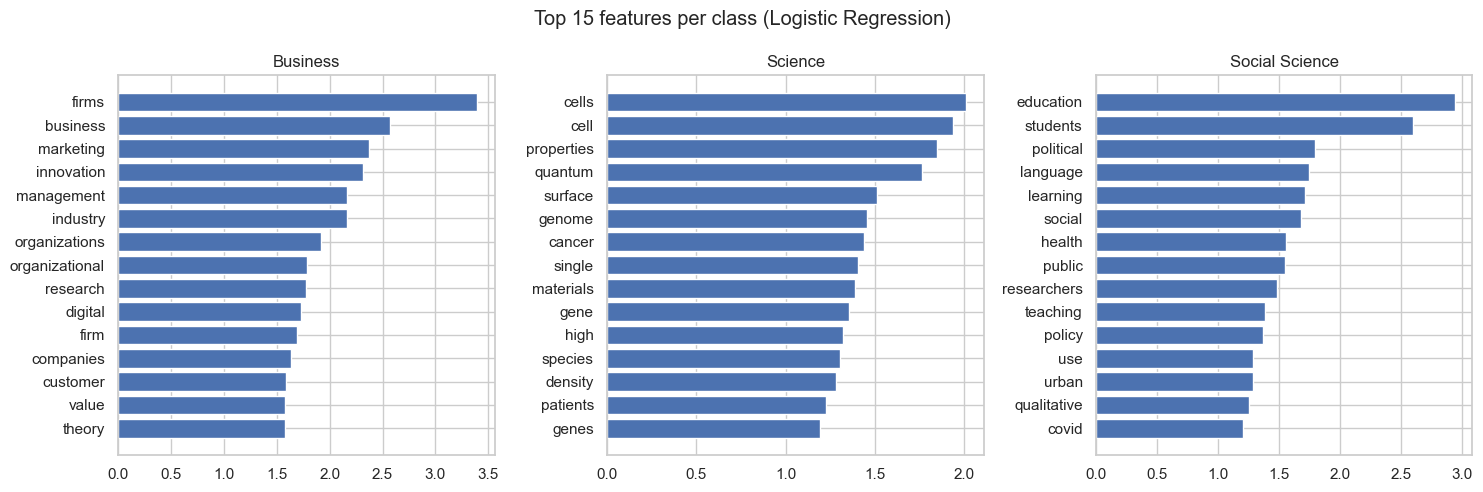

In [11]:
lr = pipes['Logistic Regression']
vocab = np.array(lr['tfidf'].get_feature_names_out())
coefs = lr['clf'].coef_
fig, axes = plt.subplots(1, len(lr['clf'].classes_), figsize=(15, 5))
for ax, cls, w in zip(axes, lr['clf'].classes_, coefs):
    idx = np.argsort(w)[-15:]
    ax.barh(vocab[idx], w[idx], color='#4C72B0'); ax.set_title(cls)
plt.suptitle('Top 15 features per class (Logistic Regression)'); plt.tight_layout(); plt.show()

## 10. Error analysis: misclassified test abstracts

In [12]:
err = pd.DataFrame({'true': y_test.values, 'pred': preds[best], 'abstract': df.loc[X_test.index, 'abstract'].str[:220].values})
err = err[err.true != err.pred]
print(f'{len(err)} errors out of {len(y_test)} ({len(err)/len(y_test):.1%})')
print(err.groupby(['true', 'pred']).size().sort_values(ascending=False))
err.head(8)

39 errors out of 300 (13.0%)
true            pred          
Business        Social Science    12
Social Science  Business           8
Business        Science            7
Science         Social Science     6
Social Science  Science            5
Science         Business           1
dtype: int64


,true,pred,abstract
12,Business,Social Science,The climate has changed significantly under th...
59,Business,Social Science,The past decade has seen significant progress ...
66,Business,Social Science,CO 2 ...
70,Business,Social Science,Open Artificial Intelligence (AI) published an...
71,Social Science,Business,The objective of this research is to examine t...
74,Business,Science,Clean and safe groundwater is the basic guaran...
81,Business,Science,Microplastic pollution has become emerging env...
87,Social Science,Science,This work presents a new nature-inspired meta-...


## 11. Save the best model (used by the Streamlit demo)

In [13]:
final = Pipeline([('tfidf', tfidf()), ('clf', models[best].__class__(**models[best].get_params()))])
final.fit(df['clean'], df['label'])            # refit on all data
import json
cm = confusion_matrix(y_test, preds[best], labels=labels).tolist()
metrics = {'best': best, 'labels': labels, 'n_total': int(len(df)), 'n_train': int(len(X_train)),
           'n_test': int(len(X_test)), 'class_counts': df['label'].value_counts().to_dict(),
           'results': results.reset_index().round(4).to_dict(orient='records'),
           'confusion_matrix': cm}
json.dump(metrics, open('metrics.json', 'w'), indent=2)
joblib.dump({'model': final, 'labels': labels, 'name': best}, 'model.joblib')
print('saved model.joblib and metrics.json  ->', best)

saved model.joblib and metrics.json  -> Logistic Regression


## 12. Quick prediction check

In [14]:
samples = ["We propose a novel catalyst for hydrogen evolution with improved quantum efficiency.",
           "This study examines how supply chain disruptions affect firm profitability and shareholder value.",
           "Using survey data, we analyse the effect of social media on political participation among youth."]
for s in samples:
    print(final.predict([clean_text(s)])[0], '<-', s[:70])

Science <- We propose a novel catalyst for hydrogen evolution with improved quant
Business <- This study examines how supply chain disruptions affect firm profitabi
Social Science <- Using survey data, we analyse the effect of social media on political 
